## Importing Libraries

In [1]:
from langchain_chroma import Chroma
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain.agents import create_agent
from langchain.tools import tool

from langchain_qdrant import FastEmbedSparse, QdrantVectorStore, RetrievalMode
from qdrant_client import QdrantClient
from dotenv import load_dotenv
load_dotenv(override=True)

/Users/animesh/anaconda3/envs/agentic-rag/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

## Loading Models and Vectordatabase

In [ ]:
llm = ChatOpenAI(
    model="gpt-6-luna",
    model_kwargs={"reasoning_effort": "none"}
)

embeddings = OpenAIEmbeddings(
    model="text-embedding-3-small",
    dimensions=1024
)

sparse_embeddings = FastEmbedSparse(model_name="Qdrant/bm25")


# Create a Qdrant client for local storage
client = QdrantClient(path="./langchain_qdrant")

vector_store = QdrantVectorStore(
    client=client,
    collection_name="pdf_collection",
    embedding=embeddings,
    sparse_embedding=sparse_embeddings,
    retrieval_mode=RetrievalMode.HYBRID,
    vector_name="dense",
    sparse_vector_name="sparse",
)

/Users/animesh/anaconda3/envs/agentic-rag/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3762: UserWarning: Parameters {'reasoning_effort'} should be specified explicitly. Instead they were passed in as part of `model_kwargs` parameter.
  if await self.run_code(code, result, async_=asy):


## Creating Tools

In [3]:
@tool
def retrieve_docs(query: str, k: int):
    """
    Search the knowledge base for information relevant to the user's question.

    Use this tool to retrieve factual information from the knowledge base.
    If the results are insufficient, search again with a refined query.

    Args:
        query: A concise, high-signal search query describing the information needed.
        k: Top k search result

    Returns:
        Relevant document chunks with their content and metadata.
    """
    retriver = vector_store.as_retriever(search_kwargs={"k": k})
    retrieved_data = retriver.invoke(query)
    context = []
    for i in retrieved_data:
        context.append(f"Content: {i.page_content}\nMetadata: {i.metadata}")

    return "\n\n".join(context)

## Building Agent

In [4]:
SYSTEM_PROMPT = """
You are an AI Knowledge Assistant. Your primary responsibility is to answer user questions accurately using information retrieved from the official knowledge base.

Available Tools:

* `retrieve_docs`: Searches the official knowledge base for relevant information.

CRITICAL INSTRUCTIONS FOR RETRIEVAL & AGENT FLOW:

1. TOOL USAGE: Use `retrieve_docs` whenever the user's question requires information from the knowledge base. Do not rely on assumptions or unsupported information.
2. RELEVANT CONTEXT: Carefully review the complete retrieved context before answering. Base your response strictly on verified information contained in the retrieved results.
3. INSUFFICIENT CONTEXT: If the retrieved context does not provide enough information to answer the question confidently, perform an additional search using a refined query designed to address the missing information. You may perform up to 2–3 searches when necessary.
4. FINAL FALLBACK: If, after the available searches, the required information still cannot be verified from the knowledge base, clearly state that you are unable to find the requested information. Do not guess, fabricate, or rely on unsupported assumptions.
5. OUT-OF-SCOPE QUERIES: If the user's question is completely unrelated to the technical domain covered by the knowledge base, politely explain that the question is outside your scope and decline to answer.

TONE AND FORMATTING:

* Maintain a helpful, direct, and professional peer-like tone.
* Use concise language and avoid unnecessary explanations.
* Break down complex technical concepts or architectures using short sentences and clear markdown headers.
* When multiple facts, steps, or pieces of evidence are required, present them using structured, easy-to-scan bullet points.
* Attribute claims to the relevant documents or sections in the retrieved context whenever such attribution is available.
  """

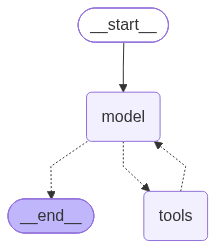

In [5]:
agent = create_agent(
    model = llm,
    tools=[retrieve_docs],
    system_prompt=SYSTEM_PROMPT
)
agent

## Querying Agent

In [6]:
events = agent.stream(
    {"messages": ("user", "summarize table-1")},
    stream_mode="values"
)

for event in events:
    latest_message = event["messages"][-1]
    latest_message.pretty_print()

================================ Human Message =================================

summarize table-1
================================== Ai Message ==================================
Tool Calls:
  retrieve_docs (call_8YxbiStCiLWbkWS3jqrhqzuo)
 Call ID: call_8YxbiStCiLWbkWS3jqrhqzuo
  Args:
    query: "Table 1"
    k: 5
================================= Tool Message =================================
Name: retrieve_docs

Content: ### Table 3 (Page 8)

| Task            |   Accuracy |
|:----------------|-----------:|
| Image retrieval |     0.6566 |
| Table retrieval |     0.4838 |
Metadata: {'chunk_id': 'table_3_rows_1_2', 'type': 'table', 'page_number': 8, 'rows_range': '1-2', 'total_rows': 2, 'columns': ['Task', 'Accuracy'], '_id': '75e08214251e4625ad6b450b43350f31', '_collection_name': 'pdf_collection'}

Content: 5.1 Comparison with Baseline
The results in Table 1 demonstrate a clear performance advantage of the PIER-QA system over the baseline. Notably, PIER-QA achieved higher similari

In [7]:
from IPython.display import Markdown
Markdown(latest_message.content)

Summary of Table 1 (Scores comparison with Baseline, p.7)

- What’s compared: Baseline vs PIER-QA across two LLM agents (GPT-3.5-turbo, GPT-4o) on Similarity and Accuracy @0.85/0.9/0.95 [Table 1, p.7].

Key results
- PIER-QA beats the Baseline for both agents across all thresholds and similarity scores [Table 1; Sec. 5.1].
- Best overall performer: PIER-QA + GPT-4o
  - Similarity: 0.8837 (highest)
  - Accuracy @0.9: 0.4944 (highest)
  - Accuracy @0.95: 0.1910 (highest) [Table 1]
- Best Accuracy @0.85: PIER-QA + GPT-3.5-turbo at 0.7640 (higher than GPT-4o’s 0.7191) [Table 1].
- Notable gains vs Baseline:
  - With GPT-4o: larger boosts at stricter thresholds (e.g., +0.0944 at @0.9; +0.0799 at @0.95) and +0.019 in Similarity.
  - With GPT-3.5-turbo: strong gain at @0.85 (+0.1751) and modest increases at @0.9 and @0.95; slight Similarity lift (+0.0027) [Table 1].

Takeaway
- The preprocessing and integrated retrieval in PIER-QA deliver consistent improvements over a plain-text baseline, with the strongest overall results when paired with GPT-4o [Table 1; Sec. 5.1].

In [8]:
events = agent.stream(
    {"messages": ("user", "tell me which model score is highest in table-1")},
    stream_mode="values"
)

for event in events:
    latest_message = event["messages"][-1]
    latest_message.pretty_print()

================================ Human Message =================================

tell me which model score is highest in table-1
================================== Ai Message ==================================
Tool Calls:
  retrieve_docs (call_3EIKDyTew8IuoLFeTmneBwai)
 Call ID: call_3EIKDyTew8IuoLFeTmneBwai
  Args:
    query: "Table-1" highest model score which model score is highest in table-1
    k: 5
================================= Tool Message =================================
Name: retrieve_docs

Content: 5.2 Investigation of different LLM agents
To understand the impact of different language models on our system's performance, we evaluated the system using three different LLM agents: GPT-4o, GPT-3.5-turbo and Llama3-70B-Instruct, and our RAG-Llama3-70B. Each LLM agent was integrated into our system and the same set of 100 questions are used for evaluation. It's also worth noting that the Llama3-70B-Instruct and our RAG-Llama3-70B were quantized at 4-bit precision for efficien

In [9]:
from IPython.display import Markdown
Markdown(latest_message.content)

From Table 1 (Page 7):

- Highest Similarity: PIER-QA with GPT-4o — 0.8837
- Highest Accuracy @0.85: PIER-QA with GPT-3.5-turbo — 0.7640
- Highest Accuracy @0.9: PIER-QA with GPT-4o — 0.4944
- Highest Accuracy @0.95: PIER-QA with GPT-4o — 0.1910

Overall single highest value in Table 1 is the Similarity score 0.8837 by PIER-QA with GPT-4o.